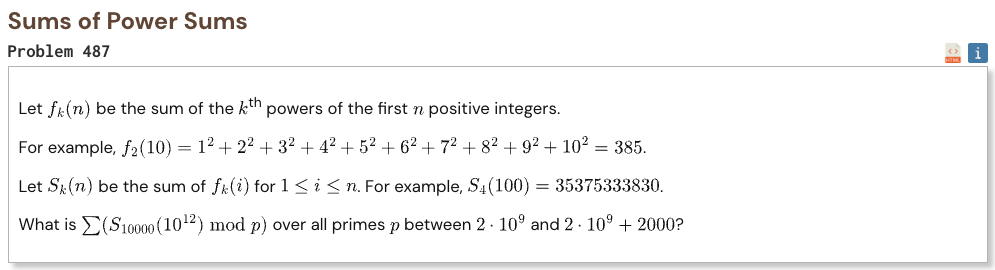

## Initial approach

- rewrite the nested power sums as one polynomial in the upper limit
- this polynomial has degree only slightly larger than 10000
- calculate its values at the first 10003 small integers
- use Lagrange interpolation to evaluate it directly at the huge target
- repeat the calculation modulo each prime in the required interval
- add all of these modular results together

In [1]:
%%time

from math import isqrt

K = 10_000
N = 10**12
LOW = 2_000_000_000
HIGH = 2_000_002_000

def small_primes(limit):
    sieve = bytearray(b"\x01") * (limit + 1)
    sieve[0:2] = b"\x00\x00"

    for p in range(2, isqrt(limit) + 1):
        if sieve[p]:
            sieve[p * p:limit + 1:p] = b"\x00" * (
                (limit - p * p) // p + 1
            )

    return [i for i in range(2, limit + 1) if sieve[i]]

trial_primes = small_primes(isqrt(HIGH))

def is_prime(n):
    for p in trial_primes:
        if p * p > n:
            break

        if n % p == 0:
            return False

    return True

def interpolate(values, x, p):
    degree = len(values) - 1

    if x <= degree:
        return values[x]

    factorial = [1] * (degree + 1)

    for i in range(1, degree + 1):
        factorial[i] = factorial[i - 1] * i % p

    inverse_factorial = [1] * (degree + 1)
    inverse_factorial[degree] = pow(
        factorial[degree],
        p - 2,
        p
    )

    for i in range(degree, 0, -1):
        inverse_factorial[i - 1] = (
            inverse_factorial[i] * i
        ) % p

    prefix = [1] * (degree + 2)
    suffix = [1] * (degree + 2)

    for i in range(degree + 1):
        prefix[i + 1] = (
            prefix[i] * (x - i)
        ) % p

    for i in range(degree, -1, -1):
        suffix[i] = (
            suffix[i + 1] * (x - i)
        ) % p

    result = 0

    for i, value in enumerate(values):
        term = value
        term = term * prefix[i] % p
        term = term * suffix[i + 1] % p
        term = term * inverse_factorial[i] % p
        term = term * inverse_factorial[degree - i] % p

        if (degree - i) % 2:
            term = -term

        result = (result + term) % p

    return result

result = 0

for p in range(LOW, HIGH + 1):
    if not is_prime(p):
        continue

    degree = K + 2
    values = [0] * (degree + 1)

    power_sum = 0
    total_sum = 0

    for i in range(1, degree + 1):
        power_sum = (
            power_sum + pow(i, K, p)
        ) % p

        total_sum = (
            total_sum + power_sum
        ) % p

        values[i] = total_sum

    value = interpolate(
        values,
        N % p,
        p
    )

    result += value

print("Result:", result)

Result: 106650212746
CPU times: user 2.38 s, sys: 45.7 ms, total: 2.43 s
Wall time: 2.56 s
